In [2]:
import numpy as np
import pandas as pd
import matplotlib as plt 

In [7]:
s = r"D:\MLtrial\archive\FuelConsumptionCo2.csv"
print(f"from URL {s} \n")
df = pd.read_csv(s)
# df.tail()
df.describe()


from URL D:\MLtrial\archive\FuelConsumptionCo2.csv 



,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [8]:
cdf = df[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
cdf.sample(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
327,3.6,6,16.5,264
699,3.7,6,12.3,283
87,3.0,6,10.0,230
170,3.6,6,11.3,260
725,3.5,6,14.0,224
1006,4.6,8,15.1,347
548,3.0,6,10.6,244
223,4.8,8,18.0,414
441,5.3,8,16.5,380


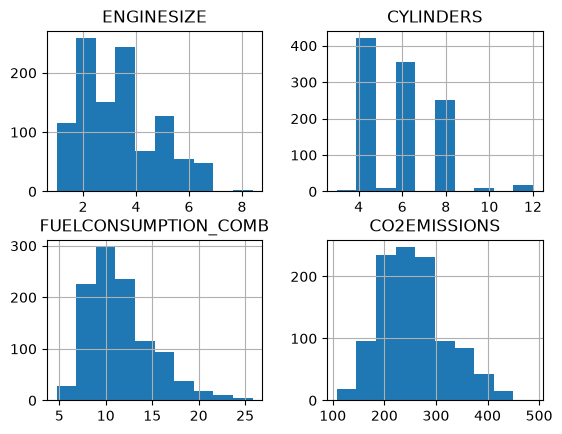

In [10]:
import matplotlib.pyplot as plt 
viz = cdf[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
viz.hist()
plt.show()

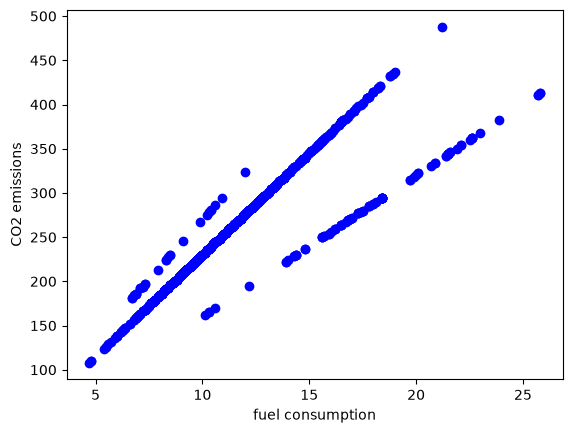

In [11]:
plt.scatter(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS, color='blue')
plt.xlabel('fuel consumption')
plt.ylabel('CO2 emissions')
plt.show()

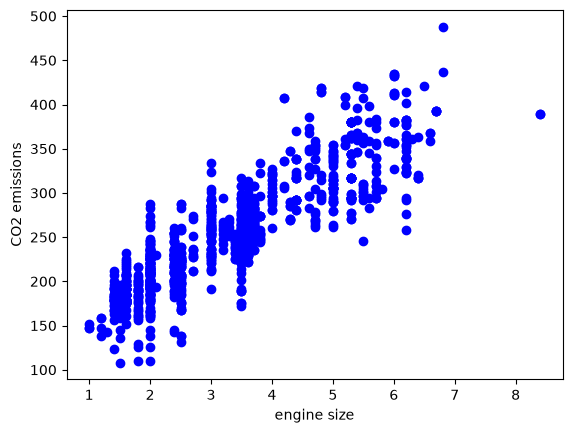

In [12]:
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS, color='blue')
plt.xlabel('engine size')
plt.ylabel('CO2 emissions')
plt.show()

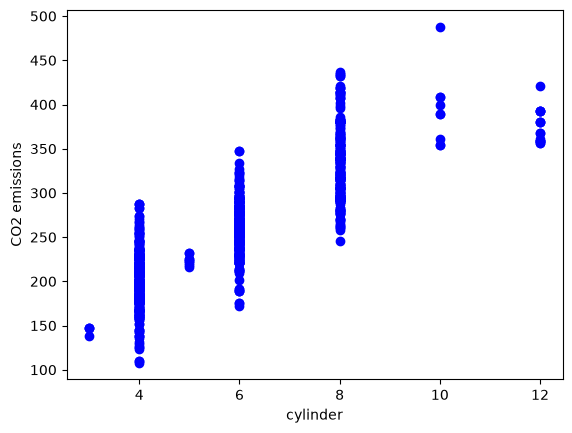

In [13]:
plt.scatter(cdf.CYLINDERS, cdf.CO2EMISSIONS, color= 'blue')
plt.xlabel('cylinder')
plt.ylabel('CO2 emissions')
plt.show()


In [31]:
X = df.iloc[1:1035 , [4]]
y = df.iloc[1:1035 , 12]
X_test = df.iloc[1035: ,[4]]
y_test = df.iloc[1035: ,12]
print(X.shape)

(1034, 1)


### Linear regression class: 

In [55]:
class LinearRegression : 
    def __init__(self, eta=0.001, n_iter = 30, ):
        self.eta = eta
        self.n_iter = n_iter
    def fit(self, X, y):
        self.losses_=[]
        
        self.w_ = np.zeros(X.shape[1])
        self.b_ = 0

        for _ in range(self.n_iter):

            y_predicted = X.dot(self.w_) + self.b_
            row_error = y - y_predicted
            loss = (row_error**2).mean()
            grad_w = -2* X.T.dot(row_error) / X.shape[0]
            grad_b = -2* row_error.mean()

            self.w_ -= self.eta *grad_w
            self.b_ -= self.eta *grad_b

            self.losses_.append(loss)
        return self 
        
    
    def predict(self, X):
        return X.dot(self.w_) + self.b_
    



     
        


In [76]:
reg = LinearRegression(eta = .01, n_iter = 650)
reg.fit(X, y)
reg.predict(X_test)


1035    186.229297
1036    194.923968
1037    194.923968
1038    194.923968
1039    194.923968
1040    194.923968
1041    194.923968
1042    168.839954
1043    186.229297
1044    186.229297
1045    216.660647
1046    216.660647
1047    264.481340
1048    194.923968
1049    194.923968
1050    264.481340
1051    194.923968
1052    194.923968
1053    194.923968
1054    264.481340
1055    238.397325
1056    216.660647
1057    216.660647
1058    238.397325
1059    247.091997
1060    238.397325
1061    247.091997
1062    238.397325
1063    247.091997
1064    238.397325
1065    247.091997
1066    247.091997
dtype: float64

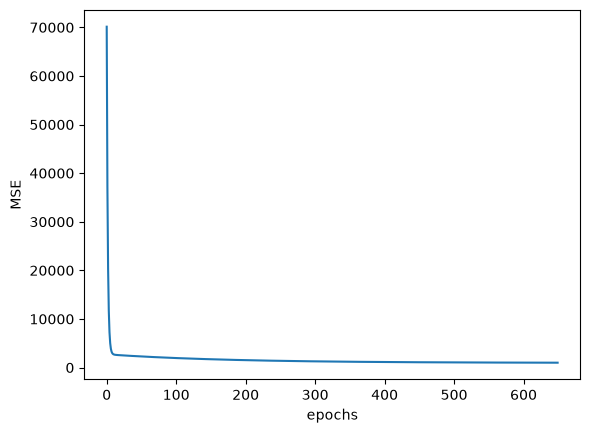

In [77]:
plt.plot(reg.losses_)
plt.xlabel('epochs')
plt.ylabel('MSE')
plt.show()

### Visualization:

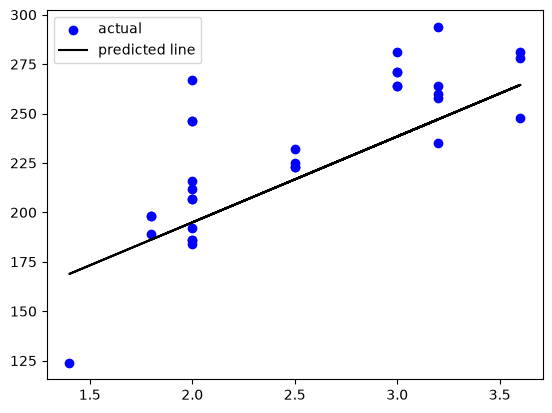

In [78]:
plt.scatter(X_test, y_test, label='actual', color= 'blue')
plt.plot(X_test, reg.predict(X_test), label= 'predicted line', color= 'black')
plt.legend()
plt.show()

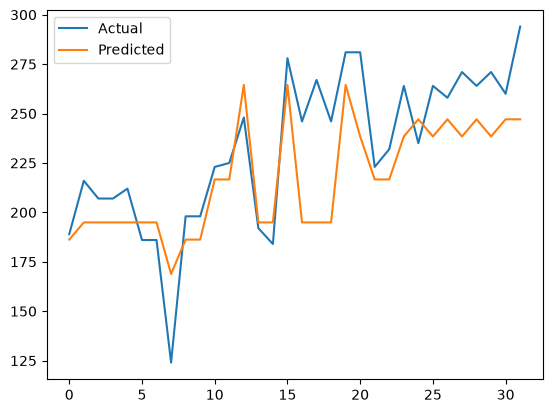

In [79]:
y_pred = reg.predict(X_test)
plt.plot(y_test.values, label="Actual")
plt.plot(y_pred.values, label="Predicted")
plt.legend()
plt.show()

In [80]:
from sklearn.metrics import r2_score
print(r2_score(y_test, y_pred))

0.49659953882685715
